# Python Fundamentals: Shipment Analytics — Step-by-Step Lab

**Goal:** Learn how each Python change affects a logistics shipment table. Work through **Steps 1–8 in order**. Each stage separates **BEFORE → CHANGE → AFTER → THINK** so you can see exactly what changed.

**How to use:** Run one code cell at a time (`Shift + Enter`). In each BEFORE cell, observe the table; in the CHANGE cell, read the comments and run the code; in the AFTER cell, compare results. Write your own responses in the **Student answer** spaces. You can modify the example numbers to experiment.

> **Color guide:** 🔵 BEFORE = starting point · 🟠 CHANGE = new code · 🟢 AFTER = effect · 🟣 THINK = your explanation. These labels complement the cell separation.

## Step 1 — Setup: imports, settings, and shipment data
**You learn:** What imports, variables and a `DataFrame` do.

- `import pandas as pd` gives us a library for tables.
- A DataFrame contains columns such as transport mode, lead time, SLA, and cost.
- **SLA_days** means the allowed delivery time in days.
- The two settings below control later steps.

### 🔵 BEFORE — What data are we starting from?
We have not created the shipment DataFrame yet. First load the tools and choose parameters.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

ACCEPTABLE_THRESHOLD_DAYS = 2  # Maximum days late to be considered "Acceptable"
FUEL_SURCHARGE_RATE = 0.07      # 7% fuel surcharge

print("Threshold:", ACCEPTABLE_THRESHOLD_DAYS, "days")
print("Fuel surcharge rate:", FUEL_SURCHARGE_RATE)

Threshold: 2 days
Fuel surcharge rate: 0.07


### 🟠 CHANGE — Create the shipment table
Each key below becomes a column. The five elements under each key become its five rows.

In [2]:
df = pd.DataFrame({
    "Mode": ["Air", "Road", "Sea", "Road", "Air"],
    "LeadTime_days": [3, 7, 18, 5, 2],
    "SLA_days": [4, 6, 18, 6, 4],
    "Cost_EUR": [120.3, 35.4, 20.6, 37.8, 122.9],
})

### 🟢 AFTER — Inspect the result
`head()` displays the first few rows; `shape` shows `(rows, columns)`.

In [3]:
display(df.head())
print("Rows and columns:", df.shape)
print("Column names:", list(df.columns))

,Mode,LeadTime_days,SLA_days,Cost_EUR
0,Air,3,4,120.3
1,Road,7,6,35.4
2,Sea,18,18,20.6
3,Road,5,6,37.8
4,Air,2,4,122.9


Rows and columns: (5, 4)
Column names: ['Mode', 'LeadTime_days', 'SLA_days', 'Cost_EUR']


### 🟣 THINK
**Q1.** How many shipments are there, and what does one row represent?

**Student answer:** _Write your answer here._

---
## Step 2 — Add `OnTime`
**Business question:** Did the shipment arrive within the agreed SLA?

**Rule:** `LeadTime_days <= SLA_days`. Equality counts as on time. Python compares every row and creates `True`/`False` values.

### 🔵 BEFORE — No `OnTime` column yet

In [4]:
display(df[["Mode", "LeadTime_days", "SLA_days"]])

,Mode,LeadTime_days,SLA_days
0,Air,3,4
1,Road,7,6
2,Sea,18,18
3,Road,5,6
4,Air,2,4


### 🟠 CHANGE — Add one calculated column
The left side, `df["OnTime"]`, names the new column. The right side calculates its values.

In [5]:
df["OnTime"] = df["LeadTime_days"] <= df["SLA_days"]

### 🟢 AFTER — Compare lead time with the boolean result

In [6]:
display(df[["Mode", "LeadTime_days", "SLA_days", "OnTime"]])
print("On-time share (%):", round(df["OnTime"].mean() * 100, 1))

,Mode,LeadTime_days,SLA_days,OnTime
0,Air,3,4,True
1,Road,7,6,False
2,Sea,18,18,True
3,Road,5,6,True
4,Air,2,4,True


On-time share (%): 80.0


### 🟣 THINK
**Q2.** Which shipment(s) are late? Why does taking the mean of `True`/`False` values yield an on-time percentage?

**Student answer:** _Write your answer here._

---
## Step 3 — Add `LateBy_days`
**Business question:** By how many days is a shipment early or late?

**Rule:** `LeadTime_days - SLA_days`. Positive = late; zero = exactly on time; negative = early. This is a **signed difference**, not a value clamped to zero.

### 🔵 BEFORE — On-time says yes/no, but not *how much*

In [7]:
display(df[["Mode", "LeadTime_days", "SLA_days", "OnTime"]])

,Mode,LeadTime_days,SLA_days,OnTime
0,Air,3,4,True
1,Road,7,6,False
2,Sea,18,18,True
3,Road,5,6,True
4,Air,2,4,True


### 🟠 CHANGE — Subtract two columns row by row

In [8]:
df["LateBy_days"] = df["LeadTime_days"] - df["SLA_days"]

### 🟢 AFTER — Positive, zero, and negative values

In [9]:
display(df[["Mode", "LeadTime_days", "SLA_days", "OnTime", "LateBy_days"]])

,Mode,LeadTime_days,SLA_days,OnTime,LateBy_days
0,Air,3,4,True,-1
1,Road,7,6,False,1
2,Sea,18,18,True,0
3,Road,5,6,True,-1
4,Air,2,4,True,-2


### 🟣 THINK
**Q3.** What does `LateBy_days = -1` mean? How does `LateBy_days` differ from `OnTime`?

**Student answer:** _Write your answer here._

---
## Step 4 — Classify performance
**Business question:** Which late shipments need attention?

**Rule order matters:**
1. **Good**: `OnTime` is `True`.
2. **Acceptable**: late, but `LateBy_days <= ACCEPTABLE_THRESHOLD_DAYS`.
3. **Critical**: more days late than the threshold.

We create a function for **one row**, then apply it across rows with `axis=1`.

### 🔵 BEFORE — Inspect the information the rule will use

In [10]:
display(df[["Mode", "OnTime", "LateBy_days"]])
print("Current acceptable threshold:", ACCEPTABLE_THRESHOLD_DAYS)

,Mode,OnTime,LateBy_days
0,Air,True,-1
1,Road,False,1
2,Sea,True,0
3,Road,True,-1
4,Air,True,-2


Current acceptable threshold: 2


### 🟠 CHANGE — Define a rule and apply it to every row
`if`/`elif`/`else` chooses exactly one label. `axis=1` tells pandas to pass each **row** to the function.

In [11]:
def performance_flag(row):
    if row["OnTime"]:
        return "Good"
    elif row["LateBy_days"] <= ACCEPTABLE_THRESHOLD_DAYS:
        return "Acceptable"
    else:
        return "Critical"


df["Performance"] = df.apply(performance_flag, axis=1)

### 🟢 AFTER — See which label each shipment receives

In [12]:
display(df[["Mode", "OnTime", "LateBy_days", "Performance"]])
print(df["Performance"].value_counts())

,Mode,OnTime,LateBy_days,Performance
0,Air,True,-1,Good
1,Road,False,1,Acceptable
2,Sea,True,0,Good
3,Road,True,-1,Good
4,Air,True,-2,Good


Performance
Good          4
Acceptable    1
Name: count, dtype: int64


### 🟣 THINK
**Q4.** Why must `OnTime` be checked before the threshold? What does `axis=1` do?

**Student answer:** _Write your answer here._

---
## Step 5 — Clean costs and apply a fuel surcharge
**Business question:** How should costs appear in reports, and what happens after an extra fuel charge?

- `round(0)` produces a rounded numeric value (typically displayed with `.0`).
- The **fuel surcharge amount** is `Cost_EUR * FUEL_SURCHARGE_RATE`.
- The **total cost including surcharge** is `Cost_EUR * (1 + FUEL_SURCHARGE_RATE)`.
- We keep both amounts so you can distinguish the surcharge from the final cost.

### 🔵 BEFORE — Original costs (unrounded)

In [13]:
display(df[["Mode", "Cost_EUR"]])

,Mode,Cost_EUR
0,Air,120.3
1,Road,35.4
2,Sea,20.6
3,Road,37.8
4,Air,122.9


### 🟠 CHANGE A — Round cost and calculate the surcharge
`.round(2)` rounds to two decimal places (cents). The `lambda` is a short function applied to each cost.

In [14]:
df["Rounded_Cost"] = df["Cost_EUR"].apply(lambda x: round(x, 0))
df["Fuel_Surcharge"] = df["Cost_EUR"] * FUEL_SURCHARGE_RATE

df["Cost_With_FuelSurcharge"] = (
    df["Cost_EUR"] + df["Fuel_Surcharge"]
).round(2)

### 🟢 AFTER A — Look at the unrounded surcharge

In [15]:
display(df[["Mode", "Cost_EUR", "Rounded_Cost", "Fuel_Surcharge", "Cost_With_FuelSurcharge"]])

,Mode,Cost_EUR,Rounded_Cost,Fuel_Surcharge,Cost_With_FuelSurcharge
0,Air,120.3,120.0,8.421,128.72
1,Road,35.4,35.0,2.478,37.88
2,Sea,20.6,21.0,1.442,22.04
3,Road,37.8,38.0,2.646,40.45
4,Air,122.9,123.0,8.603,131.50


### 🟠 CHANGE B — Student exercise: round `Fuel_Surcharge`
Uncomment the line below, then run the cell. **Do not** replace `Cost_EUR`: keep the original values available.

Hint: pandas Series support `.round(2)`.

In [16]:
# TODO: Remove the # to round the surcharge to two decimal places.
# df["Fuel_Surcharge"] = df["Fuel_Surcharge"].round(2)

### 🟢 AFTER B — Check your change
The output should show fuel surcharges to cents. Note that pandas may omit trailing zeros in display.

In [17]:
display(df[["Cost_EUR", "Fuel_Surcharge", "Cost_With_FuelSurcharge"]])

,Cost_EUR,Fuel_Surcharge,Cost_With_FuelSurcharge
0,120.3,8.421,128.72
1,35.4,2.478,37.88
2,20.6,1.442,22.04
3,37.8,2.646,40.45
4,122.9,8.603,131.50


### 🟣 THINK
**Q5.** Why might we round monetary values to two decimals? Is a fuel surcharge amount the same as total cost with the surcharge? Does rounding before adding ever matter?

**Student answer:** _Write your answer here._

---
## Step 6 — Summarize by transport mode
**Business question:** Which mode costs more, and which is more reliable?

`groupby("Mode")` makes an Air, Road, and Sea group. `agg(...)` computes multiple measures for each group:
- `Avg_Cost`: mean original `Cost_EUR`
- `OTIF`: mean of the `OnTime` boolean (**on-time rate** in this simplified example; actual OTIF also requires delivery *in full*)
- `Count`: shipment count.

### 🔵 BEFORE — Individual shipment rows

In [18]:
display(df[["Mode", "Cost_EUR", "OnTime"]])

,Mode,Cost_EUR,OnTime
0,Air,120.3,True
1,Road,35.4,False
2,Sea,20.6,True
3,Road,37.8,True
4,Air,122.9,True


### 🟠 CHANGE — Group and aggregate

In [19]:
summary = df.groupby("Mode").agg(
    Avg_Cost=("Cost_EUR", "mean"),
    OTIF=("OnTime", "mean"),
    Count=("Mode", "size"),
).round(2)

### 🟢 AFTER — One summary row per mode

,Avg_Cost,OTIF,Count
Mode,,,
Air,121.6,1.0,2
Road,36.6,0.5,2
Sea,20.6,1.0,1


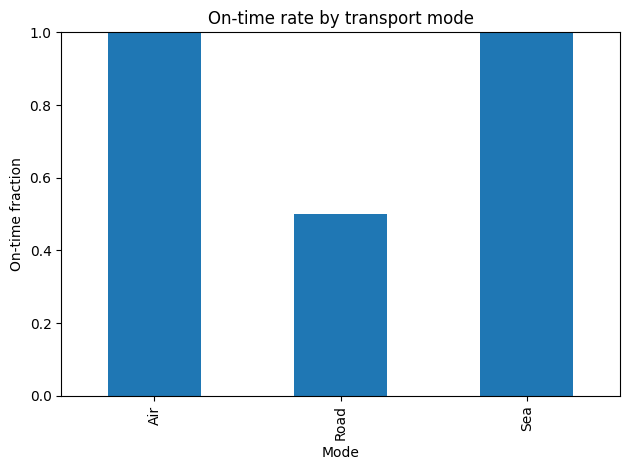

In [20]:
display(summary)
ax = summary["OTIF"].plot.bar(title="On-time rate by transport mode", ylim=(0, 1))
ax.set_ylabel("On-time fraction")
plt.tight_layout()
plt.show()

### 🟣 THINK
**Q6.** Which mode has the highest average cost? Which has the lowest on-time rate? Why is this example's `OTIF` technically only an on-time measure?

**Student answer:** _Write your answer here._

---
## Step 7 — Debug missing values
**Business question:** What do you do when shipment cost is missing?

We'll deliberately delete one Air shipment cost, observe the problem, and fill it using the average **within the same transport mode**. **Important:** The mean is calculated from the available costs, not the missing row.

After fixing cost, recalculate any derived cost columns and summary so that they stay consistent.

### 🔵 BEFORE — Look for missing values

In [21]:
print("Missing values before:")
print(df[["Mode", "Cost_EUR"]].isna().sum())
display(df[["Mode", "Cost_EUR"]])

Missing values before:
Mode        0
Cost_EUR    0
dtype: int64


,Mode,Cost_EUR
0,Air,120.3
1,Road,35.4
2,Sea,20.6
3,Road,37.8
4,Air,122.9


### 🟠 CHANGE A — Introduce one missing value
`loc[0, "Cost_EUR"]` targets row index 0 and its cost cell. `float("nan")` marks the value as missing.

In [22]:
df.loc[0, "Cost_EUR"] = float("nan")

### 🟢 AFTER A — Detect the new gap

In [23]:
print("Missing costs:", df["Cost_EUR"].isna().sum())
display(df[["Mode", "Cost_EUR"]])

Missing costs: 1


,Mode,Cost_EUR
0,Air,NaN
1,Road,35.4
2,Sea,20.6
3,Road,37.8
4,Air,122.9


### 🟠 CHANGE B — Fill using the mode's average
`transform("mean")` returns a mode-average for **each original row**, aligned to its index. `fillna(...)` uses that only where cost is missing.

In [24]:
mode_average_for_each_row = df.groupby("Mode")["Cost_EUR"].transform("mean")
print("Average cost corresponding to each row:")
display(pd.DataFrame({"Mode": df["Mode"], "Mode_Avg": mode_average_for_each_row}))

df["Cost_EUR"] = df["Cost_EUR"].fillna(mode_average_for_each_row)

Average cost corresponding to each row:


,Mode,Mode_Avg
0,Air,122.9
1,Road,36.6
2,Sea,20.6
3,Road,36.6
4,Air,122.9


### 🟢 AFTER B — Verify the repair and refresh dependent columns
This repeats the cost calculations from Step 5 and the summary from Step 6 so that nothing uses stale values.

In [25]:
print("Missing costs after:", df["Cost_EUR"].isna().sum())
df["Rounded_Cost"] = df["Cost_EUR"].round(0)
df["Fuel_Surcharge"] = (df["Cost_EUR"] * FUEL_SURCHARGE_RATE).round(2)
df["Cost_With_FuelSurcharge"] = (df["Cost_EUR"] * (1 + FUEL_SURCHARGE_RATE)).round(2)
summary = df.groupby("Mode").agg(
    Avg_Cost=("Cost_EUR", "mean"),
    OTIF=("OnTime", "mean"),
    Count=("Mode", "size"),
).round(2)
display(df[["Mode", "Cost_EUR", "Rounded_Cost", "Fuel_Surcharge"]])
display(summary)

Missing costs after: 0


,Mode,Cost_EUR,Rounded_Cost,Fuel_Surcharge
0,Air,122.9,123.0,8.60
1,Road,35.4,35.0,2.48
2,Sea,20.6,21.0,1.44
3,Road,37.8,38.0,2.65
4,Air,122.9,123.0,8.60


,Avg_Cost,OTIF,Count
Mode,,,
Air,122.9,1.0,2
Road,36.6,0.5,2
Sea,20.6,1.0,1


### 🟣 THINK
**Q7.** Which value replaces the missing Air cost? Why should we calculate an Air average rather than fill it with the average of all shipments? Which earlier results needed refreshing?

**Student answer:** _Write your answer here._

---
## Step 8 — Sensitivity: what happens when the threshold changes?
**Business question:** How sensitive are performance labels to the business rule?

The original threshold is `2` days. Try a smaller or larger value, **then reapply** the Step 4 classification. Changing a variable alone does not automatically update a previously calculated DataFrame column.

### 🔵 BEFORE — Current threshold and classifications

In [26]:
print("Threshold:", ACCEPTABLE_THRESHOLD_DAYS)
display(df[["Mode", "LateBy_days", "Performance"]])

Threshold: 2


,Mode,LateBy_days,Performance
0,Air,-1,Good
1,Road,1,Acceptable
2,Sea,0,Good
3,Road,-1,Good
4,Air,-2,Good


### 🟠 CHANGE — Experiment with a new threshold
Change `0` below to `1`, `2`, or `3` to observe the effect. The function created in Step 4 reads the latest threshold whenever it is called.

In [27]:
ACCEPTABLE_THRESHOLD_DAYS = 0  # TODO: try 0, 1, 2, or 3

df["Performance"] = df.apply(performance_flag, axis=1)

### 🟢 AFTER — Check whether category counts change

In [28]:
print("New threshold:", ACCEPTABLE_THRESHOLD_DAYS)
display(df[["Mode", "LateBy_days", "Performance"]])
print("Number of shipments in each category:")
print(df["Performance"].value_counts())

New threshold: 0


,Mode,LateBy_days,Performance
0,Air,-1,Good
1,Road,1,Critical
2,Sea,0,Good
3,Road,-1,Good
4,Air,-2,Good


Number of shipments in each category:
Performance
Good        4
Critical    1
Name: count, dtype: int64


### 🟣 THINK
**Q8.** Which shipment's category changes when moving from a 2-day to a 0-day threshold? Do `OnTime` values change? Why or why not?

**Student answer:** _Write your answer here._

---
## Final student reflection — Submit your answers

Complete these eight items in your own words after running the notebook:

| Step | Task / change | What to explain |
|---|---|---|
| 1 | Setup | How the shipment DataFrame was constructed |
| 2 | Add `OnTime` | How the comparison creates booleans |
| 3 | Add `LateBy_days` | What signed lateness means |
| 4 | Classify performance | How `if`/`elif`/`else` and `.apply(axis=1)` work |
| 5 | Clean costs | Rounding, surcharge calculation, and the rounding exercise |
| 6 | Summarize by mode | What `groupby().agg()` calculates |
| 7 | Debug missing values | How the missing cost is detected and filled |
| 8 | Sensitivity | How changing `ACCEPTABLE_THRESHOLD_DAYS` affects labels |

**Recommended submission:** Your completed notebook with code outputs and **Q1–Q8** responses.

**Rerun tip:** Use **Kernel → Restart & Run All** to reset the example and reproduce every result. Re-running just an earlier cell after Step 7 may produce different outputs because the data was modified; restarting restores the original inputs.